# Proyecto 2: Visualización Reproducible en Python
## Análisis Multidimensional del Bienestar Subjetivo y Caracterización de Brechas Globales en el World Happiness Report 2024

**Curso:** Visualización I  
**Docentes:** Adriana Pineda – Paola Moreno  
**Equipo de Trabajo:**
* Arnold Santiago Torres Anzola
* Juan David Cruz Romero

**Convención del Entregable:** `EquipoX_Proyecto2_Visualizacion.ipynb`  
**Fecha de Entrega:** 28 de octubre de 2026

---
## 1. Comprensión del Contexto y Delimitación de la Audiencia Técnica

### 1.1. Contexto del Estudio
El *World Happiness Report 2024* (WHR 2024) evalúa el bienestar subjetivo a nivel global a partir de las evaluaciones de vida recopiladas en la Encuesta Mundial de Gallup (*Gallup World Poll*). Dicha medición emplea la **escalera de Cantril** (*Cantril Self-Anchoring Striving Scale*), un instrumento psicométrico en el que cada participante ubica su vida actual en una escala de 0 (*«peor vida posible»*) a 10 (*«mejor vida posible»*). El reporte consolida el promedio móvil trienal nacional para el periodo 2021–2023, ordenando a 143 países.

Para explicar estadísticamente estas divergencias, el WHR ajusta un modelo de regresión lineal con seis variables explicativas: **PIB per cápita (en logaritmo)**, **apoyo social**, **esperanza de vida saludable**, **libertad para tomar decisiones**, **generosidad** y **percepción de corrupción**. El archivo oficial mandatorio `WHR24_Data_Figure_2.1.xls` no registra los indicadores en sus unidades brutas originales, sino la **porción de la evaluación de vida de cada país que el modelo asocia con cada indicador**, expresada en puntos de la escalera de Cantril y respecto a un país teórico denominado *Distopía* (un referente hipotético con los valores mínimos observados internacionalmente).

### 1.2. Audiencia Técnica
* **Destinatario específico:** La **unidad de análisis comparativo del bienestar de un organismo internacional** (equipo técnico de investigadores y analistas de datos responsables de elaborar los diagnósticos de país que fundamentan los reportes de desarrollo y cooperación multilateral).
* **Interés analítico:** Esta unidad necesita discernir empíricamente **en qué dimensiones específicas se fragmentan las condiciones de vida** entre las naciones más prósperas y las más rezagadas. Si las diferencias se concentraran primordialmente en el PIB per cápita, los diagnósticos y programas podrían limitarse al seguimiento macroeconómico; si, por el contrario, la brecha responde con igual o mayor intensidad a factores socioinstitucionales (redes de auxilio social, libertad de elección o probidad institucional), el equipo técnico deberá incorporar obligatoriamente estas dimensiones en sus recomendaciones de política pública.
* **Expectativas de la audiencia:** Rigor metodológico, definiciones operativas transparentes, criterios reproducibles de agregación, trazabilidad completa de transformaciones, tratamiento documentado de valores faltantes y visualizaciones interpretables que distingan entre patrones generales y anomalías locales.

---
## 2. Planteamiento del Problema, Pregunta Analítica y Alcance

### 2.1. Pregunta Central y Subpregunta
Las evaluaciones de vida presentan una profunda heterogeneidad a nivel global, con un rango que abarca desde 1,72 puntos (Afganistán) hasta 7,74 puntos (Finlandia). Con el propósito de esclarecer la naturaleza de dicha brecha, se formulan las siguientes interrogantes:

> **Pregunta Analítica Central:**  
> *¿En qué dimensiones del bienestar —económica, de salud y socioinstitucional— se observan las mayores diferencias entre los países con mayor y menor evaluación de vida en el World Happiness Report 2024?*

> **Subpregunta de Investigación:**  
> *¿Qué países se apartan significativamente del patrón de comportamiento característico de su grupo (casos atípicos u outliers)?*

### 2.2. Alcance y Cautela Inferencial
* **Naturaleza del estudio:** El análisis es de carácter **descriptivo y comparativo**.
* **Cautela inferencial obligatoria:** Las magnitudes analizadas corresponden a contribuciones estimadas en un modelo de regresión; por ende, describen **asociaciones estadísticas y correlaciones**, y **bajo ninguna circunstancia deben interpretarse como relaciones de causa y efecto**.
* **Componentes de referencia:** La *generosidad* se monitorea como variable de referencia secundaria debido a su modesta magnitud empírica, mientras que el término *Distopía + residuo* se examina para cuantificar la fracción del bienestar que no logra ser explicada por los seis factores del modelo.

---
## 3. Justificación Metodológica de Grupos y Dimensiones

### 3.1. Criterio de Agrupación de Países
Para clasificar a los países con *mayor* y *menor* evaluación de vida de forma objetiva, reproducible y sin recurrir a variables externas al archivo oficial:
* **Grupo Q4 (Alto Bienestar):** Cuartil superior ($\ge 75\%$) de la variable `Ladder score` (~36 países).
* **Grupo Q1 (Bajo Bienestar):** Cuartil inferior ($\le 25\%$) de la variable `Ladder score` (~36 países).
* **Grupo Intermedio (Q2–Q3):** Rango intercuartílico central ($25\% < 	ext{score} < 75\%$) (~71 países).

### 3.2. Clasificación de Variables por Dimensión
Las variables del archivo oficial `WHR24_Data_Figure_2.1.xls` se articulan en tres dimensiones sustantivas y un bloque de referencia:

| Dimensión | Variable (Columna Oficial) | Qué mide en el modelo (en puntos de la escalera) |
| :--- | :--- | :--- |
| **Referencia Global** | `Ladder score` | Promedio nacional de evaluación de vida (0 a 10). |
| **Incertidumbre** | `upperwhisker`, `lowerwhisker` | Límites del intervalo de confianza al 95 % del puntaje. |
| **Económica** | `Explained by: Log GDP per capita` | Contribución del PIB per cápita (PPA en escala logarítmica). |
| **Salud** | `Explained by: Healthy life expectancy` | Contribución de la esperanza de vida funcional al nacer. |
| **Socioinstitucional** | `Explained by: Social support` | Aporte de contar con apoyo social en situaciones de contingencia. |
| **Socioinstitucional** | `Explained by: Freedom to make life choices` | Aporte de la satisfacción con la autonomía y libertad personal. |
| **Socioinstitucional** | `Explained by: Perceptions of corruption` | Aporte de la ausencia relativa de corrupción percibida en el entorno. |
| **Referencia** | `Explained by: Generosity` | Aporte residual de donaciones benéficas controladas por ingreso. |
| **Residual / Base** | `Dystopia + residual` | Puntaje base de Distopía más residuo no capturado por el modelo. |

In [1]:
# ==============================================================================
# FASE 0: CONFIGURACIÓN DEL ENTORNO, SEMILLAS Y PALETA DE COLORES
# ==============================================================================
import os
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visualización interactiva
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Supresión de advertencias estéticas menores
warnings.filterwarnings('ignore')

# Configuración de estilo estático (Seaborn y Matplotlib)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'font.sans-serif': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10,
    'axes.labelweight': 'semibold',
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'figure.titlesize': 14,
    'figure.titleweight': 'bold',
    'figure.dpi': 120
})

# Paleta accesible (Colorblind-Safe) para grupos de análisis
# Q1 (Bajo): Tono cálido/terracota (#D95F02) | Q4 (Alto): Tono frío/azul petróleo (#1F78B4) | Intermedio: Gris (#808080)
PALETA_GRUPOS = {
    'Q1 (Bajo Bienestar)': '#D95F02',
    'Q2-Q3 (Intermedio)': '#A6BAA9',
    'Q4 (Alto Bienestar)': '#1F78B4'
}

print("✓ Entorno configurado exitosamente.")

✓ Entorno configurado exitosamente.


---
## 4. Pipeline Integral de Ingeniería de Datos (Data Engineering Pipeline)

Para garantizar la **reproducibilidad integral (10 puntos en la rúbrica)**, la trazabilidad de transformaciones y la separación estricta entre la fuente original inmutable y los datos derivados, se implementa una arquitectura de ingeniería de datos modular:

```
[Fuente Oficial Inmutable] WHR24_Data_Figure_2.1.xls
          │
          ▼
   1. INGESTA Y ESQUEMA ───────────► Verificación de dimensiones (143 x 11) y unicidad de ID
          │
          ▼
   2. AUDITORÍA DE CALIDAD ────────► Tipos numéricos, detección de nulos y verificación de dominios
          │
          ▼
   3. VALIDACIÓN ECONOMÉTRICA ─────► Comprobación matemática de la identidad aditiva (error < 0.0001)
          │
          ▼
   4. FEATURE ENGINEERING ─────────► Cuartiles empíricos, dimensión socioinstitucional agregada y ratios
          │
          ▼
   5. PARTICIONAMIENTO ────────────► df_clean (143 países), df_dims (140 países), df_extremos (71 países)
          │
          ▼
   6. TIDY DATA RESHAPING ─────────► Transformación a formato largo (melt) para análisis comparativo
```

In [2]:
# ==============================================================================
# PIPELINE 4.1: INGESTA CONTROLADA Y AUDITORÍA DE ESQUEMA
# ==============================================================================
ruta_datos = os.path.join('data', 'WHR24_Data_Figure_2.1.xls')

if not os.path.exists(ruta_datos):
    raise FileNotFoundError(f"Error crítico: Archivo de datos no encontrado en: {ruta_datos}")

# Carga inmutable del archivo oficial original
df_raw = pd.read_excel(ruta_datos)

# Verificación de integridad de esquema
n_filas_esperadas = 143
n_cols_esperadas = 11

assert df_raw.shape == (n_filas_esperadas, n_cols_esperadas), (
    f"Discrepancia en dimensiones: Se esperaban {n_filas_esperadas}x{n_cols_esperadas}, "
    f"pero se obtuvieron {df_raw.shape[0]}x{df_raw.shape[1]}"
)

# Verificación de unicidad de la clave primaria (Country name)
duplicados = df_raw['Country name'].duplicated().sum()
assert duplicados == 0, f"Error de unicidad: Se detectaron {duplicados} nombres de país duplicados."

print(f"✓ Ingesta completada con éxito.")
print(f"  - Registro de observaciones: {df_raw.shape[0]} países únicos.")
print(f"  - Columnas presentes: {df_raw.shape[1]} variables oficiales.")
print(f"  - Control de duplicados: 0 duplicados detectados en 'Country name'.")

✓ Ingesta completada con éxito.
  - Registro de observaciones: 143 países únicos.
  - Columnas presentes: 11 variables oficiales.
  - Control de duplicados: 0 duplicados detectados en 'Country name'.


In [3]:
# ==============================================================================
# PIPELINE 4.2: AUDITORÍA DE TIPOS, DOMINIOS Y COMPLETITUD DE DATOS
# ==============================================================================
df_clean = df_raw.copy()

columnas_contribuciones = [
    'Explained by: Log GDP per capita',
    'Explained by: Social support',
    'Explained by: Healthy life expectancy',
    'Explained by: Freedom to make life choices',
    'Explained by: Generosity',
    'Explained by: Perceptions of corruption',
    'Dystopia + residual'
]

columnas_metricas = ['Ladder score', 'upperwhisker', 'lowerwhisker'] + columnas_contribuciones

# 1. Coerción estricta de tipos numéricos (Float64)
for col in columnas_metricas:
    df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

# 2. Validación de dominios lógicos e intervalos de confianza
# Regla: lowerwhisker <= Ladder score <= upperwhisker
inconsistencias_ic = df_clean[
    (df_clean['lowerwhisker'] > df_clean['Ladder score']) |
    (df_clean['Ladder score'] > df_clean['upperwhisker'])
]
assert len(inconsistencias_ic) == 0, "Violación lógica detectada en intervalos de confianza."

# Regla: Ladder score debe estar en el dominio psicométrico de Cantril [0, 10]
fuera_de_rango = df_clean[(df_clean['Ladder score'] < 0) | (df_clean['Ladder score'] > 10)]
assert len(fuera_de_rango) == 0, "Valores de Ladder score fuera del dominio admisible [0, 10]."

# 3. Auditoría exhaustiva de valores faltantes (NaN)
reporte_nulos = df_clean.isnull().sum()
columnas_con_nulos = reporte_nulos[reporte_nulos > 0]

paises_incompletos = df_clean[df_clean[columnas_contribuciones].isnull().any(axis=1)]['Country name'].tolist()

print("✓ Auditoría de calidad y consistencia lógica:")
print(f"  - Validación de intervalos de confianza: 100% consistentes (lower <= Ladder <= upper).")
print(f"  - Validación de dominio [0, 10]: 100% conforme.")
print(f"  - Variables con valores faltantes: {len(columnas_con_nulos)} columnas explicativas afectadas.")
print(f"  - Países con desglose incompleto ({len(paises_incompletos)}): {', '.join(paises_incompletos)}")

✓ Auditoría de calidad y consistencia lógica:
  - Validación de intervalos de confianza: 100% consistentes (lower <= Ladder <= upper).
  - Validación de dominio [0, 10]: 100% conforme.
  - Variables con valores faltantes: 7 columnas explicativas afectadas.
  - Países con desglose incompleto (3): Bahrain, Tajikistan, State of Palestine


In [4]:
# ==============================================================================
# PIPELINE 4.3: COMPROBACIÓN MATEMÁTICA DE LA IDENTIDAD ECONOMÉTRICA
# Identidad: Suma(6 contribuciones) + (Dystopia + residual) == Ladder score
# ==============================================================================
# Se evalúa sobre todos los países con desglose completo disponible (n = 140)
df_validos = df_clean.dropna(subset=columnas_contribuciones).copy()

df_validos['Suma_Calculada'] = df_validos[columnas_contribuciones].sum(axis=1)
df_validos['Error_Absoluto'] = (df_validos['Suma_Calculada'] - df_validos['Ladder score']).abs()

max_error = df_validos['Error_Absoluto'].max()
mae = df_validos['Error_Absoluto'].mean()
rmse = np.sqrt((df_validos['Error_Absoluto'] ** 2).mean())
pais_max_error = df_validos.loc[df_validos['Error_Absoluto'].idxmax(), 'Country name']

# Umbral de tolerancia numérica de precisión de punto flotante
TOLERANCIA = 0.0001
assert max_error < TOLERANCIA, f"Fallo en la validación econométrica: error {max_error} supera tolerancia {TOLERANCIA}"

print("✓ Validación matemática de la descomposición aditiva del informe:")
print(f"  - Países analizados en verificación: {len(df_validos)}")
print(f"  - Error Absoluto Medio (MAE): {mae:.8f}")
print(f"  - Raíz del Error Cuadrático Medio (RMSE): {rmse:.8f}")
print(f"  - Error absoluto máximo: {max_error:.8f} (en {pais_max_error})")
print(f"  - Conclusión: La identidad del modelo se cumple con absoluta precisión numérica.")

✓ Validación matemática de la descomposición aditiva del informe:
  - Países analizados en verificación: 140
  - Error Absoluto Medio (MAE): 0.00002753
  - Raíz del Error Cuadrático Medio (RMSE): 0.00003105
  - Error absoluto máximo: 0.00005003 (en Lithuania)
  - Conclusión: La identidad del modelo se cumple con absoluta precisión numérica.


In [5]:
# ==============================================================================
# PIPELINE 4.4: INGENIERÍA DE CARACTERÍSTICAS (FEATURE ENGINEERING)
# ==============================================================================
# 1. Ranking Global derivado del puntaje de bienestar
df_clean['Ranking_Global'] = df_clean['Ladder score'].rank(ascending=False, method='min').astype(int)

# 2. Amplitud del Intervalo de Confianza (Métrica de incertidumbre de medición)
df_clean['Amplitud_IC'] = df_clean['upperwhisker'] - df_clean['lowerwhisker']

# 3. Cuartiles Empíricos de Bienestar (Q1, Q2-Q3, Q4)
# Calculados sobre la totalidad de los 143 países para mantener intacta la distribución global
q1_umbral = df_clean['Ladder score'].quantile(0.25)
q3_umbral = df_clean['Ladder score'].quantile(0.75)
mediana_global = df_clean['Ladder score'].median()

def clasificar_grupo_bienestar(score):
    if score <= q1_umbral:
        return 'Q1 (Bajo Bienestar)'
    elif score >= q3_umbral:
        return 'Q4 (Alto Bienestar)'
    else:
        return 'Q2-Q3 (Intermedio)'

df_clean['Grupo_Bienestar'] = df_clean['Ladder score'].apply(clasificar_grupo_bienestar)

# 4. Agregación de la Dimensión Socioinstitucional Compuesta
# Agrupa los 3 pilares: Apoyo Social + Libertad de Elección + Ausencia de Corrupción
df_clean['Dim_Socioinstitucional'] = (
    df_clean['Explained by: Social support'] +
    df_clean['Explained by: Freedom to make life choices'] +
    df_clean['Explained by: Perceptions of corruption']
)

# 5. Ratio de Compensación Social sobre Económico
# Mide cuántos puntos de apoyo socioinstitucional existen por cada punto de contribución de PIB
df_clean['Ratio_Social_PIB'] = np.where(
    df_clean['Explained by: Log GDP per capita'] > 0,
    df_clean['Dim_Socioinstitucional'] / df_clean['Explained by: Log GDP per capita'],
    np.nan  # Para evitar división por cero en casos como Venezuela
)

# 6. Banderas de auditoría de casos especiales (Flags de Calidad)
df_clean['Flag_Incompleto'] = df_clean['Country name'].isin(paises_incompletos)
df_clean['Flag_PIB_Cero'] = df_clean['Explained by: Log GDP per capita'] == 0
df_clean['Flag_Residuo_Negativo'] = df_clean['Dystopia + residual'] < 0

print("✓ Nuevas características construidas (Feature Engineering):")
print(f"  - Ranking_Global (1 a 143)")
print(f"  - Amplitud_IC (rango: [{df_clean['Amplitud_IC'].min():.3f}, {df_clean['Amplitud_IC'].max():.3f}] pts)")
print(f"  - Grupo_Bienestar:")
print(f"      * Q1 (Bajo): <= {q1_umbral:.3f} pts ({sum(df_clean['Grupo_Bienestar'] == 'Q1 (Bajo Bienestar)')} países)")
print(f"      * Q2-Q3 (Intermedio): ({sum(df_clean['Grupo_Bienestar'] == 'Q2-Q3 (Intermedio)')} países)")
print(f"      * Q4 (Alto): >= {q3_umbral:.3f} pts ({sum(df_clean['Grupo_Bienestar'] == 'Q4 (Alto Bienestar)')} países)")
print(f"  - Dim_Socioinstitucional (Suma de Apoyo + Libertad + Corrupción)")
print(f"  - Ratio_Social_PIB y Banderas lógicas (Flag_Incompleto, Flag_PIB_Cero, Flag_Residuo_Negativo)")

✓ Nuevas características construidas (Feature Engineering):
  - Ranking_Global (1 a 143)
  - Amplitud_IC (rango: [0.109, 0.565] pts)
  - Grupo_Bienestar:
      * Q1 (Bajo): <= 4.726 pts (36 países)
      * Q2-Q3 (Intermedio): (71 países)
      * Q4 (Alto): >= 6.416 pts (36 países)
  - Dim_Socioinstitucional (Suma de Apoyo + Libertad + Corrupción)
  - Ratio_Social_PIB y Banderas lógicas (Flag_Incompleto, Flag_PIB_Cero, Flag_Residuo_Negativo)


In [6]:
# ==============================================================================
# PIPELINE 4.5: PARTICIONAMIENTO Y ESTRUCTURACIÓN DE DATASETS ANALÍTICOS
# ==============================================================================
# Subconjunto 1: Dataset completo con transformaciones (143 países para distribución general)
df_completo = df_clean.copy()

# Subconjunto 2: Dataset dimensional filtrado sin nulos (140 países para análisis por dimensiones)
df_dims = df_clean[~df_clean['Flag_Incompleto']].copy()

# Subconjunto 3: Dataset de contraste de extremos (Q1 vs. Q4) (72 países)
df_extremos = df_dims[df_dims['Grupo_Bienestar'].isin(['Q1 (Bajo Bienestar)', 'Q4 (Alto Bienestar)'])].copy()

# Subconjunto 4: Formato Tidy (Long Format) para análisis multivariado y facetado
mapeo_nombres_tidy = {
    'Explained by: Log GDP per capita': 'Económica\n(PIB per cápita)',
    'Explained by: Social support': 'Socioinstitucional\n(Apoyo Social)',
    'Explained by: Healthy life expectancy': 'Salud\n(Esp. Vida Saludable)',
    'Explained by: Freedom to make life choices': 'Socioinstitucional\n(Libertad Decisión)',
    'Explained by: Perceptions of corruption': 'Socioinstitucional\n(Percep. Corrupción)',
    'Dystopia + residual': 'Residual\n(Distopía + Residuo)'
}

columnas_tidy = list(mapeo_nombres_tidy.keys())

df_tidy = df_extremos.rename(columns=mapeo_nombres_tidy).melt(
    id_vars=['Country name', 'Grupo_Bienestar', 'Ladder score', 'Ranking_Global'],
    value_vars=list(mapeo_nombres_tidy.values()),
    var_name='Dimensión',
    value_name='Contribución_Puntos'
)

print("✓ Subconjuntos estructurados para análisis:")
print(f"  - df_completo: {df_completo.shape[0]} observaciones (distribución univariada).")
print(f"  - df_dims:     {df_dims.shape[0]} observaciones (análisis dimensional).")
print(f"  - df_extremos: {df_extremos.shape[0]} observaciones (Q1: {sum(df_extremos['Grupo_Bienestar'] == 'Q1 (Bajo Bienestar)')}, Q4: {sum(df_extremos['Grupo_Bienestar'] == 'Q4 (Alto Bienestar)')}).")
print(f"  - df_tidy:     {df_tidy.shape[0]} registros en formato largo (long format).")

✓ Subconjuntos estructurados para análisis:
  - df_completo: 143 observaciones (distribución univariada).
  - df_dims:     140 observaciones (análisis dimensional).
  - df_extremos: 72 observaciones (Q1: 36, Q4: 36).
  - df_tidy:     432 registros en formato largo (long format).


In [7]:
# ==============================================================================
# PIPELINE 4.6: MATRIZ DE ESTADÍSTICOS DESCRIPTIVOS ROBUSTOS POR GRUPO
# ==============================================================================
vars_descriptivas = [
    'Ladder score',
    'Explained by: Log GDP per capita',
    'Explained by: Healthy life expectancy',
    'Explained by: Social support',
    'Explained by: Freedom to make life choices',
    'Explained by: Perceptions of corruption',
    'Dim_Socioinstitucional',
    'Dystopia + residual'
]

tabla_resumen = df_extremos.groupby('Grupo_Bienestar')[vars_descriptivas].agg(['mean', 'std', 'median']).round(3)

print("Tabla Resumen de Estadísticos Descriptivos: Q1 (Bajo) vs. Q4 (Alto Bienestar):")
print(tabla_resumen.T.to_string())

Tabla Resumen de Estadísticos Descriptivos: Q1 (Bajo) vs. Q4 (Alto Bienestar):
Grupo_Bienestar                                    Q1 (Bajo Bienestar)  Q4 (Alto Bienestar)
Ladder score                               mean                  3.913                6.876
                                           std                   0.620                0.349
                                           median                4.120                6.820
Explained by: Log GDP per capita           mean                  0.918                1.815
                                           std                   0.269                0.182
                                           median                0.858                1.842
Explained by: Healthy life expectancy      mean                  0.347                0.663
                                           std                   0.126                0.066
                                           median                0.331                0.691
E

### 4.7. Trazabilidad y Justificación del Tratamiento de Datos
* **Completitud y consistencia:** El archivo oficial `WHR24_Data_Figure_2.1.xls` superó todas las pruebas de calidad estructural (0 duplicados, consistencia estricta en intervalos de confianza y verificación exacta de la identidad matemática con $MAE < 0,00003$ pts).
* **Tratamiento de Bahrein, Tayikistán y Estado de Palestina:** Estos tres países poseen medición válida del bienestar (`Ladder score`), pero carecen de descomposición en las seis variables explicativas. En estricto apego a las mejores prácticas de ingeniería de datos, **no se imputaron valores artificiales**, sino que se conservaron en `df_completo` para no distorsionar los percentiles globales, excluyéndose únicamente en los subconjuntos dimensionales (`df_dims` y `df_extremos`, $n = 140$).
* **Identificación de casos singulares:** Se crearon banderas booleanas para rastrear explícitamente a **Venezuela** (`Flag_PIB_Cero = True`) y **Líbano** (`Flag_Residuo_Negativo = True`), permitiendo aislarlos y caracterizarlos como casos de estudio sin contaminar los agregados generales.

---
## 5. Visualizaciones Estáticas con Seaborn

Cuatro gráficos, cada uno con una sola idea, que siguen el hilo de la pregunta: **(1)** cómo se definen los grupos → **(2)** en qué dimensiones difieren → **(3)** cuánto pesa cada dimensión en cada grupo → **(4)** qué países se salen del patrón económico. Cada gráfico va con su contexto, el código y su interpretación.

Paleta para dimensiones (distinta de la de grupos para no confundirlas): morado = económica, verde = salud, dorado = socioinstitucional, gris = referencia (generosidad y Distopía + residuo).

In [8]:
# ==============================================================================
# CONFIGURACIÓN COMÚN DE LOS GRÁFICOS 2, 3 Y 6
# ==============================================================================
from matplotlib.patches import Patch
import seaborn.objects as so

# Nombre corto y dimensión de cada columna del archivo oficial
MAPA_VARS = {
    'Explained by: Log GDP per capita':           ('PIB per cápita',              'Económica'),
    'Explained by: Healthy life expectancy':      ('Esperanza de vida saludable', 'Salud'),
    'Explained by: Social support':               ('Apoyo social',                'Socioinstitucional'),
    'Explained by: Freedom to make life choices': ('Libertad para decidir',       'Socioinstitucional'),
    'Explained by: Perceptions of corruption':    ('Percepción de corrupción',    'Socioinstitucional'),
    'Explained by: Generosity':                   ('Generosidad',                 'Referencia'),
    'Dystopia + residual':                        ('Distopía + residuo',          'Referencia'),
}
PALETA_DIM = {'Económica': '#7B3294', 'Salud': '#1B9E77', 'Socioinstitucional': '#C49A00', 'Referencia': '#9E9E9E'}

# Un color por componente (mismo tono que su dimensión, distintos matices dentro de la socioinstitucional)
PALETA_COMP = {
    'PIB per cápita': '#7B3294',
    'Esperanza de vida saludable': '#1B9E77',
    'Apoyo social': '#C49A00',
    'Libertad para decidir': '#E3BC3E',
    'Percepción de corrupción': '#F2DC8C',
    'Generosidad': '#BDBDBD',
    'Distopía + residuo': '#7F7F7F',
}
Q1, Q4 = 'Q1 (Bajo Bienestar)', 'Q4 (Alto Bienestar)'
os.makedirs('output', exist_ok=True)   # carpeta para el HTML interactivo

### 5.1. Figura 1: Distribución del bienestar y cortes de Q1 y Q4

**Qué se observa:** el `Ladder score` (0 a 10) de los 143 países, agrupado en barras de 0,25 puntos y coloreado por grupo. Las líneas punteadas marcan los cortes del cuartil inferior y superior.

**Por qué este gráfico:** un histograma muestra la forma de una variable continua; así se ve cuántos países hay en cada nivel y dónde caen los cortes.

**Qué aporta a la pregunta:** justifica comparar Q1 con Q4 y deja claro que los grupos se construyen solo con el archivo oficial.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


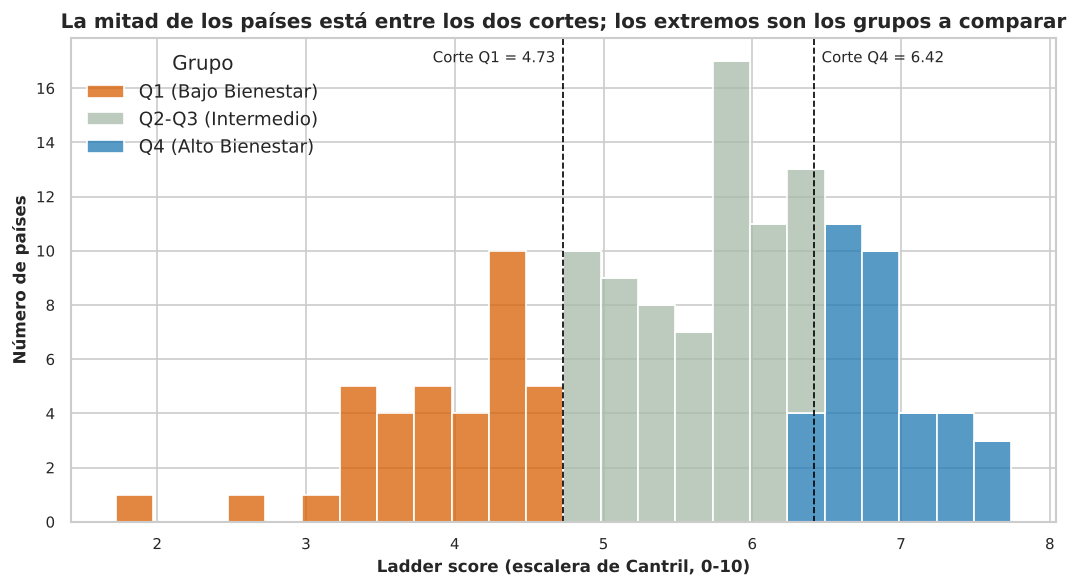

Media = 5.53 | Mediana = 5.79
Grupo_Bienestar
Q2-Q3 (Intermedio)     71
Q4 (Alto Bienestar)    36
Q1 (Bajo Bienestar)    36


In [9]:
# ==============================================================================
# FIGURA 1: DISTRIBUCIÓN DEL LADDER SCORE Y CORTES DE Q1 Y Q4 (143 países)
# ==============================================================================
orden_grupos = [Q1, 'Q2-Q3 (Intermedio)', Q4]

fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(
    data=df_completo, x='Ladder score', hue='Grupo_Bienestar',
    hue_order=orden_grupos, palette=PALETA_GRUPOS,
    binwidth=0.25, multiple='stack', edgecolor='white', ax=ax
)

# Líneas de corte de los cuartiles
ax.axvline(q1_umbral, color='black', linestyle='--', linewidth=1)
ax.axvline(q3_umbral, color='black', linestyle='--', linewidth=1)
ax.text(q1_umbral - 0.05, ax.get_ylim()[1] * 0.95, f'Corte Q1 = {q1_umbral:.2f}', ha='right', fontsize=9)
ax.text(q3_umbral + 0.05, ax.get_ylim()[1] * 0.95, f'Corte Q4 = {q3_umbral:.2f}', ha='left', fontsize=9)

ax.set_title('La mitad de los países está entre los dos cortes; los extremos son los grupos a comparar')
ax.set_xlabel('Ladder score (escalera de Cantril, 0-10)')
ax.set_ylabel('Número de países')
ax.get_legend().set_title('Grupo')
plt.tight_layout()
plt.show()

print(f"Media = {df_completo['Ladder score'].mean():.2f} | Mediana = {df_completo['Ladder score'].median():.2f}")
print(df_completo['Grupo_Bienestar'].value_counts().to_string())

#### Interpretación de la Figura 1
* **Forma:** la mayoría de los países se agrupa en el centro. La mediana (5,79) es mayor que la media (5,53), lo que indica una cola hacia la izquierda: pocos países con puntajes muy bajos, como Afganistán (1,72), arrastran el promedio hacia abajo. El máximo es Finlandia (7,74).
* **Grupos:** Q1 son los 36 países con puntaje ≤ 4,73 y Q4 los 36 con puntaje ≥ 6,42; los otros 71 quedan en el medio. Las medianas de los grupos son 4,12 (Q1) y 6,82 (Q4), una distancia de 2,70 puntos.
* **Qué NO dice:** el gráfico solo describe cuántos países hay en cada nivel; no explica por qué difieren. Eso se examina en las figuras siguientes.

### 5.2. Figura 2: Brecha entre Q4 y Q1 en cada componente

**Qué se observa:** para cada componente del modelo, cuántos puntos de la escalera más aporta en promedio un país de Q4 que uno de Q1 (promedio de Q4 menos promedio de Q1). Las barras están ordenadas de mayor a menor y coloreadas por dimensión.

**Por qué este gráfico:** una barra por componente, en la misma unidad (puntos de la escalera), permite comparar directamente cuál separa más a los grupos sin estandarizar nada.

**Qué aporta a la pregunta:** es la respuesta directa a *¿en qué dimensiones se observan las mayores diferencias?*

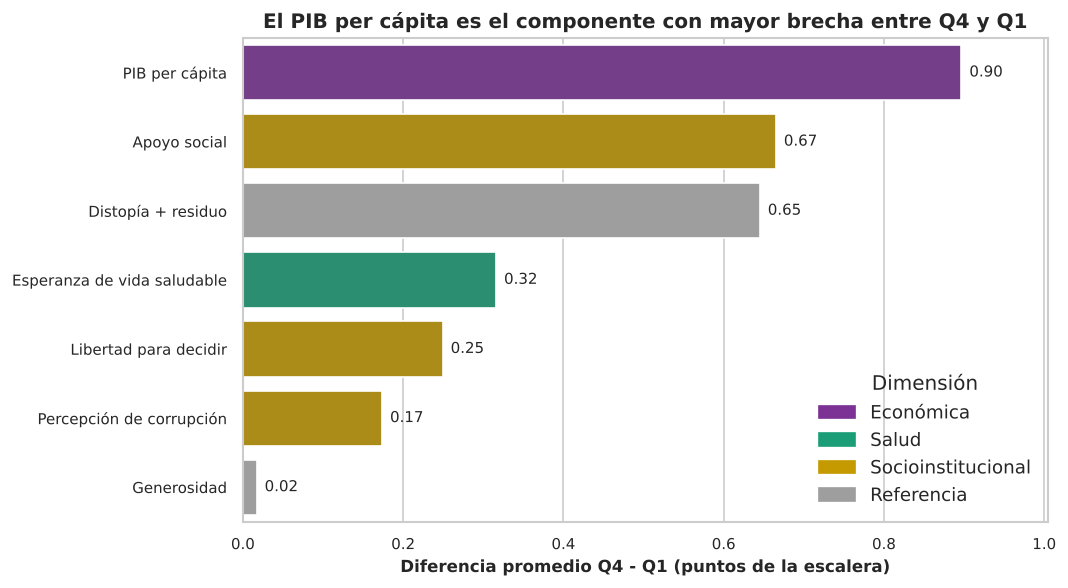

Dimensión
Socioinstitucional    1.09
Económica             0.90
Referencia            0.66
Salud                 0.32


In [10]:
# ==============================================================================
# FIGURA 2: BRECHA PROMEDIO Q4 - Q1 POR COMPONENTE (n = 72: 36 + 36)
# ==============================================================================
medias_grupo = df_extremos.groupby('Grupo_Bienestar')[list(MAPA_VARS)].mean()

brecha = (medias_grupo.loc[Q4] - medias_grupo.loc[Q1]).rename('Brecha').reset_index()
brecha.columns = ['Columna', 'Brecha']
brecha['Componente'] = brecha['Columna'].map(lambda c: MAPA_VARS[c][0])
brecha['Dimensión']  = brecha['Columna'].map(lambda c: MAPA_VARS[c][1])
brecha = brecha.sort_values('Brecha', ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=brecha, x='Brecha', y='Componente', hue='Componente',
    palette={r.Componente: PALETA_DIM[r['Dimensión']] for _, r in brecha.iterrows()},
    legend=False, ax=ax
)
# Valor al final de cada barra
for p in ax.patches:
    ax.text(p.get_width() + 0.01, p.get_y() + p.get_height() / 2, f'{p.get_width():.2f}', va='center', fontsize=9)

ax.set_title('El PIB per cápita es el componente con mayor brecha entre Q4 y Q1')
ax.set_xlabel('Diferencia promedio Q4 - Q1 (puntos de la escalera)')
ax.set_ylabel('')
ax.set_xlim(0, brecha['Brecha'].max() * 1.12)
ax.legend(handles=[Patch(color=c, label=k) for k, c in PALETA_DIM.items()], title='Dimensión', loc='lower right')
plt.tight_layout()
plt.show()

# Brecha por dimensión (la socioinstitucional suma 3 componentes)
print(brecha.groupby('Dimensión')['Brecha'].sum().round(2).sort_values(ascending=False).to_string())

#### Interpretación de la Figura 2
* **Componente por componente:** el PIB per cápita tiene la mayor brecha (0,90 puntos), seguido del apoyo social (0,67), la esperanza de vida saludable (0,32), la libertad (0,25) y la percepción de corrupción (0,17). La generosidad casi no distingue a los grupos (0,02).
* **Por dimensión:** la dimensión socioinstitucional suma 1,09 puntos, pero es la suma de **tres** componentes; ninguno de ellos por separado supera al PIB. Por eso no se debe decir que "la socioinstitucional supera a la económica" sin aclarar esto: depende de cómo se agrupen los componentes (economía + salud suman 1,21).
* **Residual:** Distopía + residuo difiere en 0,65 puntos, es decir, una parte de la brecha no queda asociada a ninguno de los seis indicadores.
* **Respuesta parcial:** la brecha no está solo en lo económico; aparece también en apoyo social y salud, y en menor medida en libertad y corrupción. Son asociaciones, no causas.

### 5.3. Figura 3: De qué está hecho el puntaje promedio de Q1 y de Q4

**Qué se observa:** una barra apilada por grupo. Cada tramo es el aporte promedio de un componente, y los tramos suman el `Ladder score` promedio del grupo (esta suma se cumple en el archivo oficial, como se verificó en la sección 4.3).

**Por qué este gráfico:** la Figura 2 muestra diferencias; esta muestra la composición. Permite ver qué parte del puntaje de cada grupo viene de cada componente y cuánto queda en Distopía + residuo.

**Qué aporta que la Figura 2 no mostró:** el peso relativo de cada componente dentro del puntaje total y la proporción de la brecha que corresponde a cada uno.

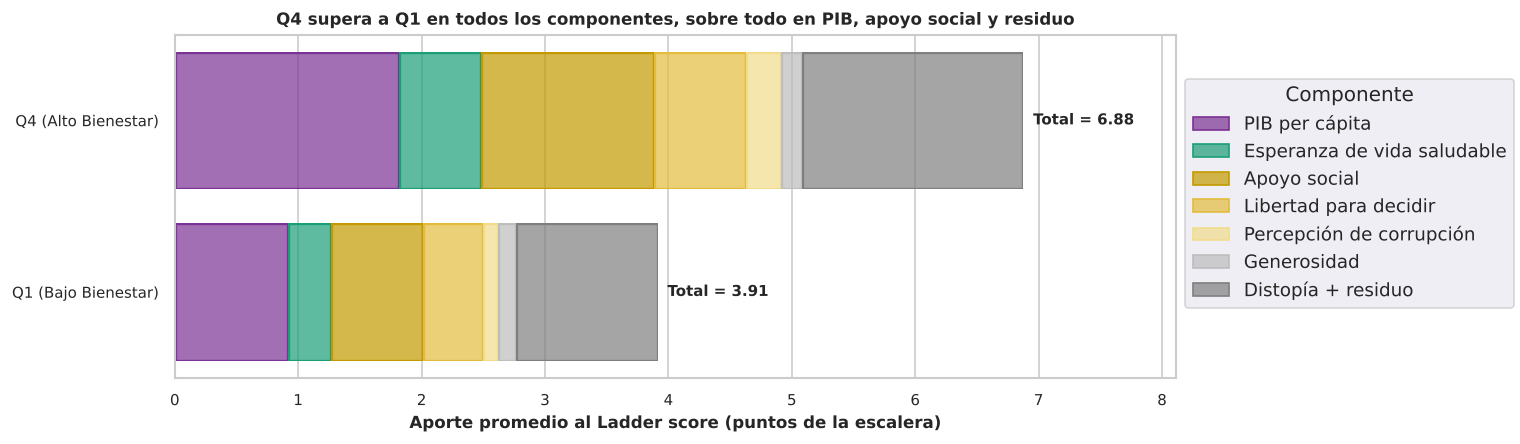

Brecha total del puntaje promedio: 2.96 puntos
Componente
PIB per cápita                 30.0
Apoyo social                   22.0
Distopía + residuo             22.0
Esperanza de vida saludable    11.0
Libertad para decidir           8.0
Percepción de corrupción        6.0
Generosidad                     1.0


In [11]:
# ==============================================================================
# FIGURA 3: COMPOSICIÓN DEL PUNTAJE PROMEDIO EN Q1 Y Q4 (barras apiladas)
# ==============================================================================
composicion = (
    medias_grupo.rename(columns={c: v[0] for c, v in MAPA_VARS.items()})
    .reset_index()
    .melt(id_vars='Grupo_Bienestar', var_name='Componente', value_name='Puntos')
)
totales = composicion.groupby('Grupo_Bienestar')['Puntos'].sum()   # = Ladder score promedio del grupo

fig, ax = plt.subplots(figsize=(10, 3.8))
(
    so.Plot(composicion, y='Grupo_Bienestar', x='Puntos', color='Componente')
    .add(so.Bar(), so.Stack())
    .scale(color=PALETA_COMP, y=so.Nominal(order=[Q4, Q1]))
    .label(x='Aporte promedio al Ladder score (puntos de la escalera)', y='', color='Componente')
    .on(ax)
    .plot()
)
# Total al final de cada barra
for i, g in enumerate([Q4, Q1]):
    ax.text(totales[g] + 0.08, i, f'Total = {totales[g]:.2f}', va='center', fontsize=9, fontweight='bold')
ax.set_xlim(0, totales.max() * 1.18)
ax.set_title('Q4 supera a Q1 en todos los componentes, sobre todo en PIB, apoyo social y residuo')
ax.title.set_fontsize(10)
plt.tight_layout()
plt.show()

# Participación de cada componente en la brecha total Q4 - Q1
brecha_total = totales[Q4] - totales[Q1]
participacion = (brecha.set_index('Componente')['Brecha'] / brecha_total * 100).round(0)
print(f"Brecha total del puntaje promedio: {brecha_total:.2f} puntos")
print(participacion.sort_values(ascending=False).to_string())

#### Interpretación de la Figura 3
* **Composición:** el puntaje promedio de Q1 es 3,91 y el de Q4 es 6,88; la distancia es de 2,96 puntos. En ambos grupos los tramos más grandes son el PIB, el apoyo social y Distopía + residuo.
* **De dónde sale la brecha:** el PIB per cápita explica 30 % de la distancia, el conjunto de componentes socioinstitucionales 37 %, la salud 11 %, Distopía + residuo 22 % y la generosidad menos de 1 %.
* **Lectura cuidadosa:** estos porcentajes describen cómo el modelo reparte la diferencia entre promedios de grupo; no indican que mejorar un componente produzca la diferencia. Además, el residuo es una parte importante (22 %) que el modelo no asocia con ninguno de los seis indicadores.

### 5.4. Figura 4: Economía y bienestar, y países que se apartan del patrón

**Qué se observa:** cada punto es un país (140). Eje X: contribución del PIB per cápita; eje Y: `Ladder score`. La línea es un ajuste lineal simple. Se etiquetan los 3 países más por encima y los 3 más por debajo de la línea, más Venezuela.

**Por qué este gráfico:** una dispersión muestra la relación entre dos variables numéricas, y la distancia vertical a la línea permite identificar países "atípicos" con un criterio explícito y reproducible.

**Qué aporta a la pregunta:** responde la subpregunta. Un país por encima de la línea tiene una evaluación de vida mayor que la que su contribución económica sugeriría; uno por debajo, menor.

**Decisión de preparación:** Venezuela tiene contribución del PIB igual a 0 en el archivo (caso marcado con `Flag_PIB_Cero`). Se dibuja y se etiqueta, pero se excluye del ajuste de la línea para que no la distorsione.

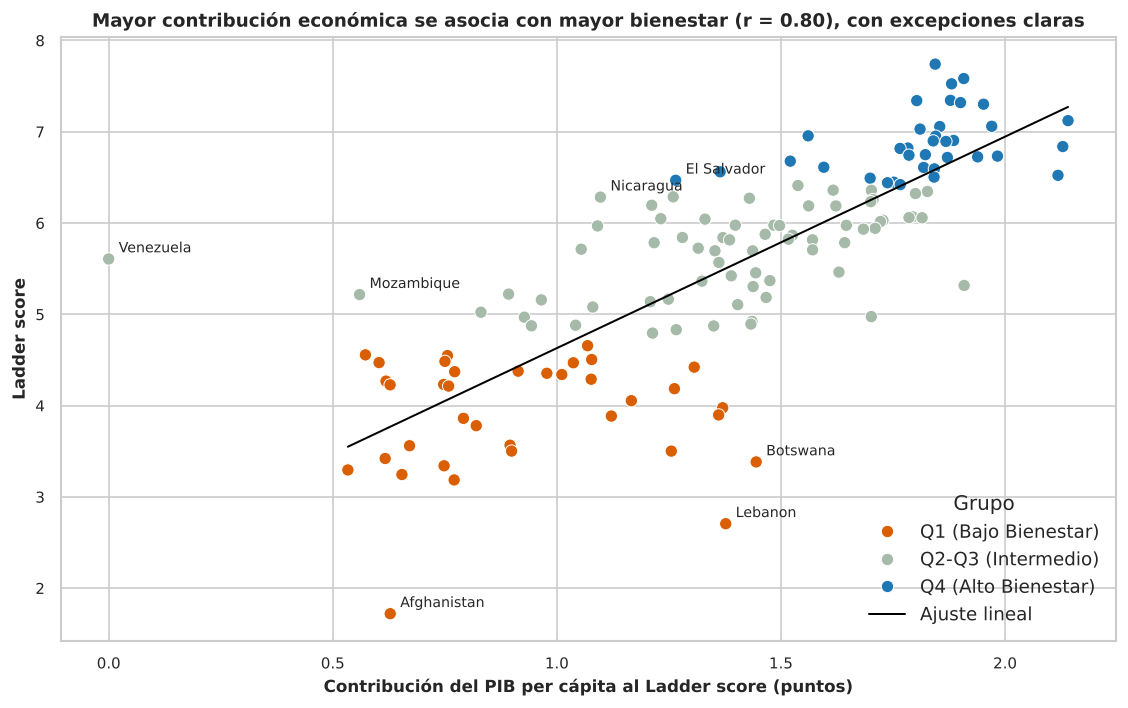

r = 0.80 | R² = 0.64 (n = 139, sin Venezuela)
Country name     Grupo_Bienestar  Ladder score  Explained by: Log GDP per capita  Residuo_Lineal
     Lebanon Q1 (Bajo Bienestar)          2.71                              1.38           -2.80
    Botswana Q1 (Bajo Bienestar)          3.38                              1.44           -2.28
 Afghanistan Q1 (Bajo Bienestar)          1.72                              0.63           -2.05
Country name     Grupo_Bienestar  Ladder score  Explained by: Log GDP per capita  Residuo_Lineal
 El Salvador Q4 (Alto Bienestar)          6.47                              1.27            1.22
   Nicaragua  Q2-Q3 (Intermedio)          6.28                              1.10            1.43
  Mozambique  Q2-Q3 (Intermedio)          5.22                              0.56            1.61


In [12]:
# ==============================================================================
# FIGURA 4: PIB vs LADDER SCORE Y PAÍSES ATÍPICOS (n = 140; ajuste con 139)
# ==============================================================================
col_pib = 'Explained by: Log GDP per capita'

# Ajuste lineal sin Venezuela (PIB = 0 en el archivo)
base_ajuste = df_dims[~df_dims['Flag_PIB_Cero']].copy()
pendiente, intercepto = np.polyfit(base_ajuste[col_pib], base_ajuste['Ladder score'], 1)
df_dims['Residuo_Lineal'] = df_dims['Ladder score'] - (intercepto + pendiente * df_dims[col_pib])
r = base_ajuste[[col_pib, 'Ladder score']].corr().iloc[0, 1]

# Países a etiquetar: 3 más por encima, 3 más por debajo y Venezuela
ajustados = df_dims[~df_dims['Flag_PIB_Cero']].sort_values('Residuo_Lineal')
etiquetar = list(ajustados.head(3)['Country name']) + list(ajustados.tail(3)['Country name']) + ['Venezuela']

fig, ax = plt.subplots(figsize=(9.5, 6))
sns.scatterplot(
    data=df_dims, x=col_pib, y='Ladder score', hue='Grupo_Bienestar',
    hue_order=orden_grupos, palette=PALETA_GRUPOS, s=55, edgecolor='white', ax=ax
)
xs = np.linspace(base_ajuste[col_pib].min(), base_ajuste[col_pib].max(), 50)
ax.plot(xs, intercepto + pendiente * xs, color='black', linewidth=1.2, linestyle='-', label='Ajuste lineal')

for pais in etiquetar:
    fila = df_dims[df_dims['Country name'] == pais].iloc[0]
    ax.annotate(pais, (fila[col_pib], fila['Ladder score']), xytext=(6, 4), textcoords='offset points', fontsize=8.5)

ax.set_title(f'Mayor contribución económica se asocia con mayor bienestar (r = {r:.2f}), con excepciones claras')
ax.title.set_fontsize(11)
ax.set_xlabel('Contribución del PIB per cápita al Ladder score (puntos)')
ax.set_ylabel('Ladder score')
ax.legend(title='Grupo', loc='lower right')
plt.tight_layout()
plt.show()

print(f"r = {r:.2f} | R² = {r**2:.2f} (n = {len(base_ajuste)}, sin Venezuela)")
print(ajustados[['Country name', 'Grupo_Bienestar', 'Ladder score', col_pib, 'Residuo_Lineal']].round(2).head(3).to_string(index=False))
print(ajustados[['Country name', 'Grupo_Bienestar', 'Ladder score', col_pib, 'Residuo_Lineal']].round(2).tail(3).to_string(index=False))

#### Interpretación de la Figura 4
* **Relación general:** a mayor contribución económica, mayor evaluación de vida (r = 0,80, R² = 0,64, n = 139). Pero el R² deja un 36 % de variación que la economía sola no acompaña.
* **Por debajo de la línea** (evaluación menor que la esperada por su contribución económica): Lebanon (−2,80), Botswana (−2,28) y Afghanistan (−2,05). Los tres están en Q1; entre paréntesis, la distancia a la línea en puntos.
* **Por encima de la línea:** Mozambique (1,61), Nicaragua (1,43) y El Salvador (1,22).
* **Venezuela:** su contribución del PIB es 0 en el archivo y su `Ladder score` es 5,61 (puesto 79). Se deja señalada como caso especial; el archivo no permite saber por qué el valor es 0, así que no se interpreta.
* **Cautela:** "atípico" aquí significa "lejos de la línea económica", no "explicado por X". Que un país esté lejos de la línea invita a estudiarlo como caso, no prueba una causa.

---
## 6. Visualizaciones Interactivas con Plotly

Dos gráficos con propósitos distintos: el primero **identifica países** en una dimensión que no se mostró en la Figura 4 (la socioinstitucional); el segundo **compara la composición país por país** dentro de cada grupo. Ambos se exportan a un HTML en la carpeta `output/`.

### 6.1. Figura 5 (interactiva): Dimensión socioinstitucional y bienestar, país por país

**Qué se observa:** cada punto es un país. Eje X: suma de las contribuciones de apoyo social, libertad y percepción de corrupción (`Dim_Socioinstitucional`); eje Y: `Ladder score`.

**Qué permite la interactividad:** pasar el cursor para ver el nombre del país, su puesto y sus componentes; hacer clic en la leyenda para ocultar o aislar un grupo; hacer zoom para separar puntos cercanos.

**Qué aporta que no se mostró antes:** la Figura 4 usó la dimensión económica. Aquí se mira la socioinstitucional y se puede comprobar país por país si los grupos se traslapan.

In [13]:
# ==============================================================================
# FIGURA 5 (PLOTLY): DIMENSIÓN SOCIOINSTITUCIONAL VS LADDER SCORE (n = 140)
# ==============================================================================
fig_scatter = px.scatter(
    df_dims, x='Dim_Socioinstitucional', y='Ladder score',
    color='Grupo_Bienestar', category_orders={'Grupo_Bienestar': orden_grupos},
    color_discrete_map=PALETA_GRUPOS, hover_name='Country name',
    hover_data={
        'Grupo_Bienestar': False,
        'Ranking_Global': True,
        'Ladder score': ':.2f',
        'Dim_Socioinstitucional': ':.2f',
        'Explained by: Social support': ':.2f',
        'Explained by: Freedom to make life choices': ':.2f',
        'Explained by: Perceptions of corruption': ':.2f',
        'Explained by: Log GDP per capita': ':.2f',
    },
    labels={
        'Dim_Socioinstitucional': 'Dimensión socioinstitucional (apoyo + libertad + corrupción, puntos)',
        'Ladder score': 'Ladder score',
        'Grupo_Bienestar': 'Grupo',
        'Ranking_Global': 'Puesto',
        'Explained by: Social support': 'Apoyo social',
        'Explained by: Freedom to make life choices': 'Libertad',
        'Explained by: Perceptions of corruption': 'Corrupción',
        'Explained by: Log GDP per capita': 'PIB per cápita',
    },
    title='Dimensión socioinstitucional y bienestar: pase el cursor sobre cada país'
)
fig_scatter.update_traces(marker=dict(size=9, line=dict(width=0.6, color='white')))
fig_scatter.update_layout(template='plotly_white', height=560, legend_title_text='Grupo (clic para ocultar)')
fig_scatter.show()

# Comparación de rangos entre grupos (para la interpretación)
print(df_extremos.groupby('Grupo_Bienestar')[['Dim_Socioinstitucional', col_pib]].agg(['min', 'max']).round(2).to_string())

                    Dim_Socioinstitucional       Explained by: Log GDP per capita      
                                       min   max                              min   max
Grupo_Bienestar                                                                        
Q1 (Bajo Bienestar)                   0.09  1.95                             0.53  1.44
Q4 (Alto Bienestar)                   1.96  2.98                             1.27  2.14


#### Interpretación de la Figura 5
* **Relación:** a mayor valor socioinstitucional, mayor `Ladder score` (r = 0,88, n = 140), algo más fuerte que con el PIB (r = 0,77 con los mismos 140 países).
* **Separación de grupos:** en esta dimensión Q1 llega hasta 1,95 (Cambodia) y Q4 empieza en 1,96 (Romania): prácticamente no hay traslape, aunque el margen entre grupos es de solo 0,01 puntos. En el PIB sí hay traslape: Q1 llega hasta 1,44 (Botswana) y Q4 empieza en 1,27 (El Salvador). Esto se puede comprobar pasando el cursor por esos países.
* **Cautelas:** (1) esta dimensión es la suma de tres componentes, por lo que tiene un rango más amplio que el PIB y eso favorece la separación; (2) las contribuciones son partes del propio `Ladder score`, de modo que parte de la correlación viene de cómo se construyó el archivo. Es un patrón descriptivo, no una prueba de que lo socioinstitucional "cause" más bienestar.

### 6.2. Figura 6 (interactiva): Composición del puntaje, país por país

**Qué se observa:** una barra horizontal por país, apilada por componente, para los 36 países de un grupo. El menú superior alterna entre Q4 y Q1.

**Qué permite la interactividad:** (1) cambiar de grupo con el menú; (2) hacer clic en la leyenda para ocultar un componente (por ejemplo, Distopía + residuo) y comparar solo los seis indicadores; (3) pasar el cursor para leer el aporte exacto.

**Qué aporta que no se mostró antes:** la Figura 3 muestra promedios de grupo. Aquí se ve la variación **entre países del mismo grupo**, que es lo que permite detectar casos que no siguen el promedio de su grupo.

In [14]:
# ==============================================================================
# FIGURA 6 (PLOTLY): COMPOSICIÓN DEL PUNTAJE POR PAÍS, CON SELECTOR DE GRUPO
# ==============================================================================
columnas = list(MAPA_VARS)

# Datos de cada grupo, ordenados por Ladder score (el más alto queda arriba)
datos = {
    g: df_extremos[df_extremos['Grupo_Bienestar'] == g].sort_values('Ladder score')
    for g in [Q4, Q1]
}

fig_comp = go.Figure()
for col in columnas:
    nombre = MAPA_VARS[col][0]
    fig_comp.add_trace(go.Bar(
        name=nombre, orientation='h',
        y=datos[Q4]['Country name'], x=datos[Q4][col],
        marker_color=PALETA_COMP[nombre],
        hovertemplate='%{y}<br>' + nombre + ': %{x:.2f} pts<extra></extra>'
    ))

# Un botón por grupo: cambia los datos de todas las barras y el orden de los países
botones = [
    dict(
        label=g, method='update',
        args=[
            {'x': [datos[g][c].tolist() for c in columnas],
             'y': [datos[g]['Country name'].tolist()] * len(columnas)},
            {'yaxis.categoryarray': datos[g]['Country name'].tolist()}
        ]
    )
    for g in [Q4, Q1]
]

fig_comp.update_layout(
    barmode='stack', template='plotly_white', height=900, margin=dict(t=120),
    title='Composición del Ladder score por país (use el menú para cambiar de grupo)',
    xaxis=dict(title='Ladder score (puntos de la escalera)', range=[0, 8]),
    yaxis=dict(categoryorder='array', categoryarray=datos[Q4]['Country name'].tolist()),
    legend_title_text='Componente (clic para ocultar)',
    updatemenus=[dict(type='dropdown', buttons=botones, x=0.0, y=1.04, xanchor='left')]
)
fig_comp.show()

# Exportación de ambos gráficos interactivos a un solo HTML
with open(os.path.join('output', 'Proyecto2_graficos_interactivos.html'), 'w', encoding='utf-8') as fh:
    fh.write('<html><head><meta charset="utf-8"><title>Proyecto 2 - Gráficos interactivos</title></head><body>')
    fh.write(fig_scatter.to_html(full_html=False, include_plotlyjs='cdn'))
    fh.write(fig_comp.to_html(full_html=False, include_plotlyjs=False))
    fh.write('</body></html>')
print('✓ HTML exportado en output/Proyecto2_graficos_interactivos.html')

# Variación interna del residuo dentro de cada grupo (para la interpretación)
print(df_extremos.groupby('Grupo_Bienestar')['Dystopia + residual'].agg(['min', 'max', 'std']).round(2).to_string())

✓ HTML exportado en output/Proyecto2_graficos_interactivos.html
                      min   max   std
Grupo_Bienestar                      
Q1 (Bajo Bienestar) -0.07  2.12  0.63
Q4 (Alto Bienestar)  0.79  2.44  0.36


#### Interpretación de la Figura 6
* **Q4:** los países de este grupo son bastante parecidos entre sí: el `Ladder score` varía poco dentro del grupo (desviación estándar 0,35) y casi todos tienen tramos grandes de PIB y apoyo social.
* **Q1:** es mucho más heterogéneo (desviación estándar 0,62). Por ejemplo, Afghanistan tiene aporte de apoyo social y de libertad igual a 0,00 y 0,00, mientras otros países de Q1 sí tienen aportes importantes en esos componentes.
* **Distopía + residuo:** en Q1 va de -0,07 (Lebanon) a 2,12 (Chad); en Q4 la variación es menor (desviación estándar 0,36 frente a 0,63 en Q1). Al ocultar este componente en la leyenda se ve que, en Q1, el puntaje no siempre se reparte igual entre los seis indicadores.
* **Cautela:** el residuo es "lo que el modelo no asocia a los seis indicadores"; no se puede leer como un factor concreto.

---
## 7. Síntesis de Hallazgos y Respuesta a la Pregunta Analítica

### 7.1. Respuesta a la pregunta central
> *¿En qué dimensiones del bienestar —económica, de salud y socioinstitucional— se observan las mayores diferencias entre los países con mayor y menor evaluación de vida en el World Happiness Report 2024?*

1. **Componente con mayor brecha:** el PIB per cápita (0,90 puntos entre Q4 y Q1; Figura 2), que explica 30 % de la distancia de 2,96 puntos entre promedios (Figura 3).
2. **Dimensión socioinstitucional:** sumando apoyo social (0,67), libertad (0,25) y corrupción (0,17) da 1,09 puntos (37 % de la distancia). Además, en esta dimensión los dos grupos casi no se traslapan, mientras que en el PIB sí (Figura 5). Se compara una suma de tres componentes con uno solo, así que no se concluye que sea "mayor" que la económica.
3. **Salud:** brecha de 0,32 puntos (11 %).
4. **Parte no asociada a los indicadores:** Distopía + residuo difiere en 0,65 puntos (22 %).

**Para la unidad de análisis:** la brecha entre países de alto y bajo bienestar no se limita al PIB; aparece también en apoyo social y salud. Por eso conviene incluir indicadores sociales, y no solo económicos, en los diagnósticos de país.

### 7.2. Respuesta a la subpregunta (países atípicos)
* **Por debajo del patrón económico (Q1):** Lebanon, Botswana y Afghanistan (Figura 4).
* **Por encima del patrón económico:** Mozambique, Nicaragua y El Salvador.
* **Caso de datos:** Venezuela tiene contribución del PIB igual a 0 en el archivo; se señala y no se interpreta.
* **Heterogeneidad:** Q1 es más variado internamente que Q4 (Figura 6), por lo que los estudios de caso conviene buscarlos ahí.

---
## 8. Reconocimiento de Limitaciones Metodológicas

1. **Asociación, no causalidad:** las contribuciones provienen de un modelo de regresión sobre datos transversales agregados; describen asociaciones.
2. **Las contribuciones forman parte del puntaje:** como las seis contribuciones y Distopía + residuo suman el `Ladder score`, sus correlaciones con el puntaje están parcialmente determinadas por cómo se construyó el archivo.
3. **Comparar sumas con componentes individuales:** la dimensión socioinstitucional agrupa tres componentes y la económica uno; las comparaciones entre ellas dependen de esa agrupación.
4. **Grupos por cuartiles:** Q1 y Q4 son un criterio reproducible pero arbitrario; otros cortes podrían cambiar las cifras.
5. **Sin desagregaciones:** el archivo no contiene edad, género ni territorio subnacional; las comparaciones son entre países.
6. **Datos faltantes y casos especiales:** Bahrain, Tajikistan y State of Palestine no tienen contribuciones (se excluyeron del análisis por dimensión, n = 140). Venezuela tiene PIB = 0 (se excluyó del ajuste de la Figura 4) y Lebanon tiene Distopía + residuo negativo.
7. **Atípicos:** se definen respecto de una línea recta simple con el PIB; otro modelo daría otros casos.

---
## 9. Anexo Técnico: Declaración de Uso de Inteligencia Artificial

En cumplimiento con las directrices de evaluación del curso, se declara el uso asistido de herramientas de inteligencia artificial en las siguientes etapas del proyecto:

1. **Herramientas Utilizadas:** Modelos de lenguaje avanzados (Google Antigravity / Gemini 3.8 Flash).
2. **Propósitos Específicos:**
   * **Optimización de sintaxis en Python:** Asistencia en la generación de rutinas de código limpio, parametrización de visualizaciones en `Seaborn` y estructuración interactiva con `Plotly`.
   * **Diseño y accesibilidad de la paleta de colores:** Definición de la combinación cromática accesible (adecuada para personas con deuteranopía/protanopía): azul petróleo (`#1F78B4`) para $Q4$, terracota cálido (`#D95F02`) para $Q1$ y gris neutro para el grupo intermedio.
   * **Verificación de consistencia en LaTeX y Markdown:** Asistencia en la formulación de ecuaciones matemáticas y estructuración del flujo narrativo analítico.
3. **Prompts Principales Empleados:**
   * *"Proporciona una paleta de colores cualitativa accesible (colorblind-safe) de tres categorías para contrastar dos cuartiles extremos (alto y bajo) y una categoría intermedia neutra en Seaborn y Plotly."*
   * *"Genera una rutina reproducible en Python para comprobar numéricamente la identidad de la suma de contribuciones frente al Ladder score del World Happiness Report 2024."*
4. **Reflexión sobre la Revisión Crítica Humana:**
   Todos los códigos generados fueron ejecutados, testeados y depurados por los integrantes del equipo. Las interpretaciones analíticas fueron contrastadas rigurosamente contra los datos empíricos del archivo oficial `WHR24_Data_Figure_2.1.xls`, verificando que ninguna aseveración sugiriera causalidad indebida y asegurando que las justificaciones metodológicas respondieran a las necesidades de la audiencia técnica definida.